# Linear Regression

X1 = total overall reported crime rate per 1 million residents

X2 = reported violent crime rate per 100,000 residents

X3 = annual police funding in $/resident

X4 = % of people 25 years+ with 4 yrs. of high school

X5 = % of 16 to 19 year-olds not in highschool and not highschool graduates.

X6 = % of 18 to 24 year-olds in college

X7 = % of people 25 years+ with at least 4 years of college

Reference: Life In America's Small Cities, By G.S. Thomas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

crime_df = pd.read_csv("crime_data.csv")
crime_df.head()

,X1,X2,X3,X4,X5,X6,X7
0,478,184,40,74,11,31,20
1,494,213,32,72,11,43,18
2,643,347,57,70,18,16,16
3,341,565,31,71,11,25,19
4,773,327,67,72,9,29,24


In [2]:
crime_df.corr()

,X1,X2,X3,X4,X5,X6,X7
X1,1.000000,0.756505,0.533198,-0.135459,0.322519,-0.175224,-0.026283
X2,0.756505,1.000000,0.509339,-0.184445,0.291031,-0.199070,-0.045570
X3,0.533198,0.509339,1.000000,0.120265,0.311526,-0.277475,0.124502
X4,-0.135459,-0.184445,0.120265,1.000000,-0.537162,0.182364,0.681072
X5,0.322519,0.291031,0.311526,-0.537162,1.000000,-0.626953,-0.513958
X6,-0.175224,-0.199070,-0.277475,0.182364,-0.626953,1.000000,0.591663
X7,-0.026283,-0.045570,0.124502,0.681072,-0.513958,0.591663,1.000000


<Axes: >

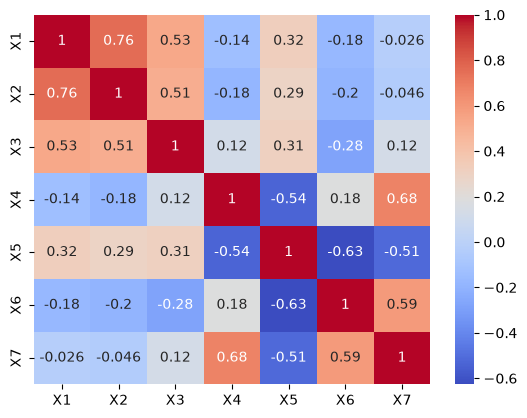

In [3]:
sns.heatmap(crime_df.corr(), annot=True, cmap="coolwarm")

In [5]:
y = crime_df["X1"]
X = crime_df[["X2", "X5"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.3, 
                                                    random_state=10)

In [ ]:
from sklearn.linear_model import LinearRegression
"""
LinearRegression is a class and we are creating an instance of it to fit our training data.
"""

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

y_pred

Mean Squared Error: 68337.31963309417


In [11]:
#does accuracy matter here? no, because this is regression, not classification
from sklearn.metrics import accuracy_score
accuracy_score = accuracy_score(y_test, lr.predict(X_test))
accuracy_score

ValueError: Classification metrics can't handle a mix of multiclass and continuous targets

In [ ]:
# mean-squared error
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred)
mse

# r-squared
r_squared = lr.score(X_test, y_test)

print(f"Mean Squared Error: {mse}") #this MSE is extremely high 
print(f"R-squared: {r_squared}") #surprisngly decent R-squared

lr.coef_
lr.intercept_

print(f"Coefficients: {lr.coef_}")
print(f"Intercept: {lr.intercept_}")
# equation produced? 
# y = X2*.335 + X5*8.458 + 372.96

Mean Squared Error: 68337.31963309417
R-squared: 0.5675800011202556
Coefficients: [0.33541896 8.45822449]
Intercept: 372.96000428392983


# OLS Regression 
OLS (ordinary least squares) regression is a type of linear regression that lets you handle interactions as well as features that done have interactions. WIth OLS regression you can incorporate features that are correlated with each other

In [14]:
! pip3 install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 34.1 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [16]:
from statsmodels.formula.api import ols

model = ols("X1 ~ X2 + X5", data=crime_df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     X1   R-squared:                       0.584
Model:                            OLS   Adj. R-squared:                  0.566
Method:                 Least Squares   F-statistic:                     32.96
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.13e-09
Time:                        20:06:41   Log-Likelihood:                -332.70
No. Observations:                  50   AIC:                             671.4
Df Residuals:                      47   BIC:                             677.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    405.3870     76.434      5.304      0.0

In [17]:
x1_w_int = ols("X1 ~ X2*X3 + X5", data=crime_df).fit()
print(x1_w_int.summary())

                            OLS Regression Results                            
Dep. Variable:                     X1   R-squared:                       0.624
Model:                            OLS   Adj. R-squared:                  0.591
Method:                 Least Squares   F-statistic:                     18.70
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           4.06e-09
Time:                        20:07:17   Log-Likelihood:                -330.13
No. Observations:                  50   AIC:                             670.3
Df Residuals:                      45   BIC:                             679.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    181.9831    129.348      1.407      0.1

# Logistic Regression

In [19]:
diabetes_df = pd.read_csv("diabetes.csv")
diabetes_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = diabetes_df.drop("Outcome", axis=1)
y = diabetes_df["Outcome"]

# stratification can be (be surely isnt always) useful
# it tries to split the test data into groups that represent 
# the distribution of the target variable. So, it keeps groups
# in the data properly represented. ie doesnt just test on old people.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    random_state=10, stratify=y)

# Standarize our data
# I would not necessarily use this. It is naive. But it is another tool for your toolbox
# by all means, explore other standardizartion techniques
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train


array([[-0.8335243 ,  1.9289985 , -3.50565463, ...,  1.46255598,
        -0.56706481,  0.68171797],
       [ 1.24810698,  1.110994  , -0.35572047, ...,  0.27420583,
         0.27357092,  1.11146625],
       [ 0.95073108, -0.23053339, -0.15249891, ...,  0.12087033,
        -0.64436465,  0.76766762],
       ...,
       [-0.8335243 ,  0.81651238, -0.66055281, ..., -0.27524639,
         0.34120828, -0.34967792],
       [-0.8335243 , -0.91765717,  0.05072264, ..., -0.18580067,
        -0.46077753, -0.86537586],
       [-0.5361484 , -0.91765717, -0.25410969, ...,  0.78532418,
         0.6954992 , -0.86537586]])

In [24]:
# simplest logistic regression approach
regression = LogisticRegression(random_state=10)
regression.fit(X_train, y_train)
y_pred = regression.predict(X_test)

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"accuracy: {accuracy}")

#What is really going to be the best metric for determing how good our model is? 
# Becuse its diabetes data, recall is best because we want to minimize false negatives, 
# i.e., we want to correctly identify as many diabetic patients as possible.
from sklearn.metrics import recall_score
recall = recall_score(y_test, y_pred)
print(f"recall: {recall}")

accuracy: 0.8116883116883117
recall: 0.6851851851851852


(<Figure size 640x480 with 3 Axes>,
 {('0', '0'): (0.0, 0.0, 0.6461200491051238, 0.8770764119601329),
  ('0', '1'): (0.0,
   0.8803986710963454,
   0.6461200491051238,
   0.11960132890365448),
  ('1', '0'): (0.6510951734832332,
   0.0,
   0.34890482651676685,
   0.3137689184200812),
  ('1', '1'): (0.6510951734832332,
   0.31709117755629385,
   0.34890482651676685,
   0.6829088224437061)})

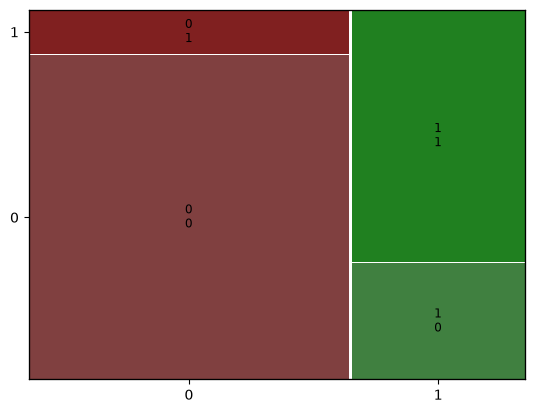

In [28]:
# Visualize the confusion matrix using a mosaic plot
from sklearn.metrics import confusion_matrix
from statsmodels.graphics.mosaicplot import mosaic
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred) # add the labels for the confusion matrix
mosaic(cm)


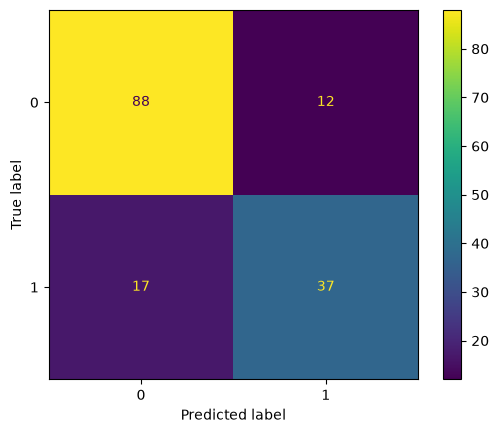

In [29]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

In [32]:
def precision_and_recall(calc_type:str, tp:int, fp:int, fn:int):
    """
    Docstring: THis function produces prection and recall results 
    based on what is passed
    """
    if calc_type == "precision":
        return tp / (tp + fp) if (tp + fp) > 0 else 0
    elif calc_type == "recall":
        return tp / (tp + fn) if (tp + fn) > 0 else 0
    else:
        raise ValueError("calc_type must be 'precision' or 'recall'")

In [35]:
precision_and_recall("precision", tp=37, fp=12, fn=17)

0.7551020408163265

In [34]:
precision_and_recall("recall", tp=37, fp=12, fn=17)

0.6851851851851852